# Alzheimer MRI – DGI Adversarial Detection
## Stage 1: Dataset audit and class-distribution verification

This notebook begins the reproducible implementation described in the manuscript. It:
- accepts the dataset ZIP downloaded from Mendeley Data;
- extracts it in the Colab runtime;
- locates image files and infers labels from class-folder names;
- reports class counts, image dimensions, and unreadable files;
- displays representative images.

**Important:** The manuscript does not currently specify the original train/validation/test counts. This first stage audits the downloaded dataset only. We will choose and document a stratified split after confirming the folder structure and counts. Do not describe a newly created split as the original split used in the submitted experiments.


## 1. Install and import packages

In [17]:
!pip -q install pillow pandas matplotlib scikit-learn

import os, zipfile, shutil, random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Environment ready")


Environment ready


## 2. Upload the downloaded dataset ZIP

If your dataset is already in Google Drive, you can mount Drive and set `ZIP_PATH` manually in the alternative cell below. Otherwise, upload the ZIP directly.


In [18]:
from google.colab import files

uploaded = files.upload()  # Select the Mendeley dataset ZIP file
zip_files = [name for name in uploaded.keys() if name.lower().endswith(".zip")]

if not zip_files:
    raise ValueError("No ZIP file was uploaded. Please upload the dataset ZIP.")

ZIP_PATH = zip_files[0]
print("Uploaded:", ZIP_PATH)

Saving Alzheimer (Preprocessed Data) (1).zip to Alzheimer (Preprocessed Data) (1) (1).zip
Uploaded: Alzheimer (Preprocessed Data) (1) (1).zip


### Alternative: load the ZIP from Google Drive (optional)

Run this cell instead of uploading if the ZIP is stored in Drive. Edit the path to match your file.


In [19]:
# from google.colab import drive
# drive.mount('/content/drive')
# ZIP_PATH = '/content/drive/MyDrive/dataset.zip'  # edit this path
# assert os.path.exists(ZIP_PATH), f"ZIP not found: {ZIP_PATH}"


## 3. Extract the dataset

In [20]:
import sys

# Check if ZIP_PATH is defined in the workspace
if 'ZIP_PATH' not in globals():
    print("Error: 'ZIP_PATH' is not defined.")
    print("Please ensure you have either:")
    print("  1. Successfully uploaded the dataset ZIP in section 2 above, or")
    print("  2. Un-commented and run the Google Drive alternative cell directly above to define ZIP_PATH.")
else:
    EXTRACT_DIR = Path("/content/alzheimer_mri_dataset")
    if EXTRACT_DIR.exists():
        shutil.rmtree(EXTRACT_DIR)
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(EXTRACT_DIR)

    print("Extracted to:", EXTRACT_DIR)
    print("Top-level entries:")
    for p in list(EXTRACT_DIR.iterdir())[:30]:
        print(" -", p.name, "(directory)" if p.is_dir() else "(file)")

Extracted to: /content/alzheimer_mri_dataset
Top-level entries:
 - Alzheimer (Preprocessed Data) (directory)


## 4. Locate images and infer class labels

The expected class names in the dataset are typically variants of:
- MildDemented
- ModerateDemented
- NonDemented
- VeryMildDemented

Labels are inferred from the **nearest parent folder** containing one of these class names. If your ZIP has a different folder structure, inspect the printed examples and we will adapt the loader rather than guessing.


In [21]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

CLASS_ALIASES = {
    "milddemented": "Mild Demented",
    "moderatedemented": "Moderate Demented",
    "nondemented": "Non-Demented",
    "verymilddemented": "Very Mild Demented",
}

def normalize_token(s):
    # Keep only alphanumeric characters (removes underscores, spaces, etc.)
    return "".join(ch.lower() for ch in s if ch.isalnum())

records = []
unmatched = []

for path in EXTRACT_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in IMAGE_EXTS:
        label = None
        for parent in [path.parent, *path.parents]:
            token = normalize_token(parent.name)
            if token in CLASS_ALIASES:
                label = CLASS_ALIASES[token]
                break
            if parent == EXTRACT_DIR:
                break
        if label is None:
            unmatched.append(str(path))
        else:
            records.append({"path": str(path), "label": label})

df = pd.DataFrame(records)
print("Recognized image files:", len(df))
print("Images with unrecognized class folder:", len(unmatched))
if unmatched[:10]:
    print("\nExamples of unrecognized paths:")
    for p in unmatched[:10]:
        print(p)

if df.empty:
    raise ValueError(
        "No images were assigned to a recognized class. Please inspect the folder names "
        "above and share the folder structure so we can adjust the label parser."
    )

df.head()

Recognized image files: 6400
Images with unrecognized class folder: 0


,path,label
0,/content/alzheimer_mri_dataset/Alzheimer (Prep...,Moderate Demented
1,/content/alzheimer_mri_dataset/Alzheimer (Prep...,Moderate Demented
2,/content/alzheimer_mri_dataset/Alzheimer (Prep...,Moderate Demented
3,/content/alzheimer_mri_dataset/Alzheimer (Prep...,Moderate Demented
4,/content/alzheimer_mri_dataset/Alzheimer (Prep...,Moderate Demented


## 5. Class distribution and basic image validation

,Class,Image count,Percentage
0,Mild Demented,896,14.0
1,Moderate Demented,64,1.0
2,Non-Demented,3200,50.0
3,Very Mild Demented,2240,35.0


Total recognized images: 6400


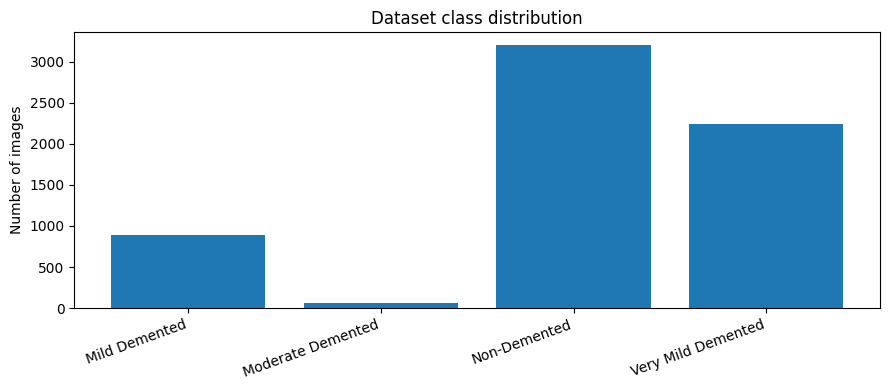

Readable images: 6400
Unreadable images: 0
Most common original dimensions:


,Width x Height,Count
0,"(128, 128)",6400


In [22]:
class_counts = df["label"].value_counts().reindex(
    ["Mild Demented", "Moderate Demented", "Non-Demented", "Very Mild Demented"],
    fill_value=0
)
distribution = pd.DataFrame({
    "Class": class_counts.index,
    "Image count": class_counts.values,
    "Percentage": (class_counts.values / len(df) * 100).round(2)
})
display(distribution)
print("Total recognized images:", int(class_counts.sum()))

plt.figure(figsize=(9, 4))
plt.bar(distribution["Class"], distribution["Image count"])
plt.title("Dataset class distribution")
plt.ylabel("Number of images")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

valid_rows, bad_rows, dimensions = [], [], Counter()
for row in df.itertuples(index=False):
    try:
        with Image.open(row.path) as im:
            im.verify()
        with Image.open(row.path) as im:
            dimensions[im.size] += 1
        valid_rows.append({"path": row.path, "label": row.label})
    except Exception as e:
        bad_rows.append({"path": row.path, "error": str(e)})

df_valid = pd.DataFrame(valid_rows)
print("Readable images:", len(df_valid))
print("Unreadable images:", len(bad_rows))
print("Most common original dimensions:")
display(pd.DataFrame(dimensions.most_common(15), columns=["Width x Height", "Count"]))

if bad_rows:
    display(pd.DataFrame(bad_rows).head(10))


## 6. Display representative images

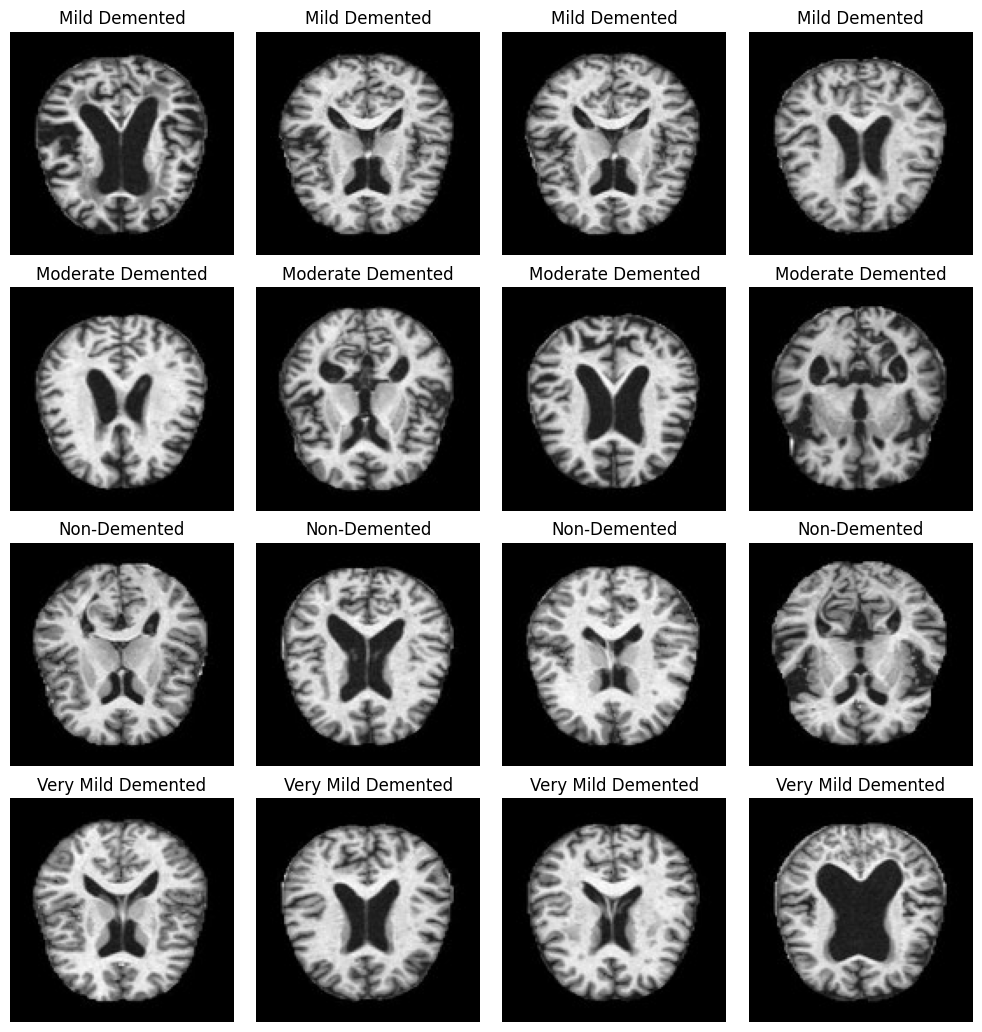

In [23]:
classes = [c for c in class_counts.index if class_counts[c] > 0]
fig, axes = plt.subplots(len(classes), 4, figsize=(10, 2.6 * len(classes)))
if len(classes) == 1:
    axes = np.array([axes])

for i, cls in enumerate(classes):
    samples = df_valid[df_valid["label"] == cls].sample(
        n=min(4, (df_valid["label"] == cls).sum()), random_state=SEED
    )
    for j, row in enumerate(samples.itertuples(index=False)):
        with Image.open(row.path) as im:
            axes[i, j].imshow(im.convert("RGB"), cmap="gray")
        axes[i, j].set_title(cls)
        axes[i, j].axis("off")
    for j in range(len(samples), 4):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


## 7. Save the audit report

This CSV contains the recognized image paths and class labels. It is an index of the local Colab dataset, not the images themselves.


In [24]:
AUDIT_CSV = "/content/alzheimer_dataset_index.csv"
df_valid.to_csv(AUDIT_CSV, index=False)
print("Saved:", AUDIT_CSV)

from google.colab import files
files.download(AUDIT_CSV)


Saved: /content/alzheimer_dataset_index.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Stage 1 completion checklist

Before moving to the CNN and graph implementation, record:
1. The total readable image count.
2. The four class counts.
3. Whether any images were not recognized or could not be opened.
4. Whether the observed class distribution matches the repository description.

**Do not assume the dataset is balanced.** The class distribution must be measured from the actual downloaded files. The next notebook stage will use the verified data and an explicitly documented stratified split.
